# Idea B: sailing performance

How fast did sailing ships go depending on the wind angle and wind force? From two consecutive daily positions we can compute the ship's speed and course, and compare the course with the logged wind direction.

Uses the clean subset saved by `01_inspect_data.ipynb` (run that first).

In [29]:
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

df = pd.read_pickle(ROOT / "data" / "cliwoc_clean.pkl")
print(df.shape)
df.head()

(287113, 42)


,Year,Month,Day,latitude,longitude,D,W,AllWindDirections,AllWindForces,SLP,AT,Weather,Gusts,Rain,Fog,Snow,Thunder,Hail,SeaIce,Nationality,LogbookLanguage,ShipName,ShipType,Company,LogbookIdent,VoyageIni,VoyageFrom,VoyageTo,Anchored,Distance,DistTravelledUnits,Release,date,calm,variable_wind,wind_dir,wind_ms,beaufort,u,v,nat,voyage_id
0,1827,8,16,-6.92,103.10,136.0,NaN,ZO,NaN,NaN,NaN,GOED WEER,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DUTCH,DUTCH,ABEL TASMAN,NaN,MAR,MAR_D23905_1164,18270816,BATAVIA,NEDERLAND,0,30.75,ENGELSE,CLIWOC VERSION 1.0,1827-08-16,False,False,136.0,NaN,NaN,NaN,NaN,DUTCH,MAR_D23905_1164 | 18270816
1,1827,8,17,-8.27,100.47,135.0,46.0,ZO,BRAMZEILSKOELTE EN MINDERE KOELTE,NaN,NaN,GOED WEER,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DUTCH,DUTCH,ABEL TASMAN,NaN,MAR,MAR_D23905_1164,18270816,BATAVIA,NEDERLAND,0,41.75,ENGELSE,CLIWOC VERSION 1.0,1827-08-17,False,False,135.0,4.6,3.0,-3.252691,3.252691,DUTCH,MAR_D23905_1164 | 18270816
2,1827,8,18,-9.43,97.72,135.0,46.0,ZO,BRAMZEILSKOELTE EN MINDERE KOELTE,NaN,NaN,GOED WEER,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DUTCH,DUTCH,ABEL TASMAN,NaN,MAR,MAR_D23905_1164,18270816,BATAVIA,NEDERLAND,0,42.00,ENGELSE,CLIWOC VERSION 1.0,1827-08-18,False,False,135.0,4.6,3.0,-3.252691,3.252691,DUTCH,MAR_D23905_1164 | 18270816
3,1827,8,19,-10.77,95.02,135.0,46.0,ZO,BRAMZEILSKOELTE EN MINDERE KOELTE,NaN,NaN,GOED WEER,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DUTCH,DUTCH,ABEL TASMAN,NaN,MAR,MAR_D23905_1164,18270816,BATAVIA,NEDERLAND,0,41.75,ENGELSE,CLIWOC VERSION 1.0,1827-08-19,False,False,135.0,4.6,3.0,-3.252691,3.252691,DUTCH,MAR_D23905_1164 | 18270816
4,1827,8,20,-12.07,92.83,113.0,26.0,OZO,FLAUWE BRAMZEILSKOELTE,NaN,NaN,GOED WEER,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DUTCH,DUTCH,ABEL TASMAN,NaN,MAR,MAR_D23905_1164,18270816,BATAVIA,NEDERLAND,0,37.50,ENGELSE,CLIWOC VERSION 1.0,1827-08-20,False,False,113.0,2.6,2.0,-2.393313,1.015901,DUTCH,MAR_D23905_1164 | 18270816


## 1. One record per voyage per day

Some voyage-days have more than one record, for two reasons:
- **several ships under one logbook ID**: 26 IDs contain more than one ship, e.g. `ADM_177_2421` in 1789 holds the frigate *Thetis* and the snow *Zwaluw*, sailing together to Batavia. Mixed into one track, it zig-zags between the two ships. Fix: add the ship name to the voyage key.
- **several observations on the same day** (e.g. at 4:00, noon and 20:00).

For the second case, keep the record that
1. has a position,
2. is the noon observation (noon is when the position was fixed),
3. has a wind entry.

Remaining ties: take the row that comes first in the file.

In [30]:
# TimeOB (hour of the observation) is not in the clean pickle, so take it from the raw file.
# The pickle kept the row numbers of the TSV, so the two line up on the index.
df["TimeOB"] = pd.read_csv(ROOT / "data" / "CLIWOC21.tsv", sep="\t", usecols=["TimeOB"])["TimeOB"]

days = df.dropna(subset=["date"]).copy()
print(f"dropped {len(df) - len(days)} rows without a valid date")

dropped 375 rows without a valid date


In [31]:
# Example: one logbook ID, two ships
EXAMPLE = "ADM_177_2421 | 17890414"
cols = ["ShipName", "ShipType", "date", "TimeOB", "latitude", "longitude", "D", "W"]
ex = days[days["voyage_id"] == EXAMPLE]
ex.loc[ex.duplicated("date", keep=False), cols].sort_values("date").head(8)

,ShipName,ShipType,date,TimeOB,latitude,longitude,D,W
253955,THETIS,FREGAT,1789-04-14,12.0,50.00,-4.66,55.0,46.0
286294,ZWALUW,SNAUW,1789-04-14,12.0,49.93,-5.15,55.0,46.0
286295,ZWALUW,SNAUW,1789-04-15,12.0,49.22,-6.72,179.0,0.0
253956,THETIS,FREGAT,1789-04-15,12.0,49.20,-6.92,190.0,46.0
253957,THETIS,FREGAT,1789-04-16,12.0,49.18,-7.72,133.0,93.0
286296,ZWALUW,SNAUW,1789-04-16,12.0,NaN,NaN,158.0,93.0
253958,THETIS,FREGAT,1789-04-17,12.0,49.30,-7.80,211.0,67.0
286297,ZWALUW,SNAUW,1789-04-17,12.0,NaN,NaN,248.0,93.0


In [32]:
before = days.copy()   # kept for the before/after check below

# 1) Several ships under one logbook ID -> add the ship name to the voyage key
n_ships = days.groupby("voyage_id")["ShipName"].nunique()
print(f"{(n_ships > 1).sum()} voyage IDs contain more than one ship")
days["voyage_id"] = days["voyage_id"] + " | " + days["ShipName"].astype(str)

# 2) What is still duplicated now: several observations on the same day
dup = days.duplicated(["voyage_id", "date"], keep=False)
n_groups = days[dup].groupby(["voyage_id", "date"]).ngroups
print(f"{dup.sum():,} rows share their voyage-day with another row ({n_groups:,} voyage-days)")
print("observation hour of those rows:", days.loc[dup, "TimeOB"].value_counts().to_dict())

# Sort each voyage-day so the preferred record comes first (False sorts before True), then keep it
days = days.assign(
    _no_pos=days["latitude"].isna(),
    _not_noon=days["TimeOB"].ne(12),
    _no_wind=days["D"].isna(),
    _row=days.index,
)
days = (days.sort_values(["voyage_id", "date", "_no_pos", "_not_noon", "_no_wind", "_row"])
            .drop_duplicates(["voyage_id", "date"], keep="first")
            .drop(columns=["_no_pos", "_not_noon", "_no_wind", "_row"]))

assert not days.duplicated(["voyage_id", "date"]).any()
print(f"\n{len(days):,} voyage-days kept, {len(before) - len(days):,} duplicate rows removed")

26 voyage IDs contain more than one ship
9,891 rows share their voyage-day with another row (3,498 voyage-days)
observation hour of those rows: {12.0: 4481, 4.0: 2746, 20.0: 2631, 16.0: 22, 6.0: 3, 8.0: 2, 18.0: 1, 0.0: 1, 5.0: 1, 23.0: 1, 3.0: 1, 11.0: 1}

280,345 voyage-days kept, 6,393 duplicate rows removed


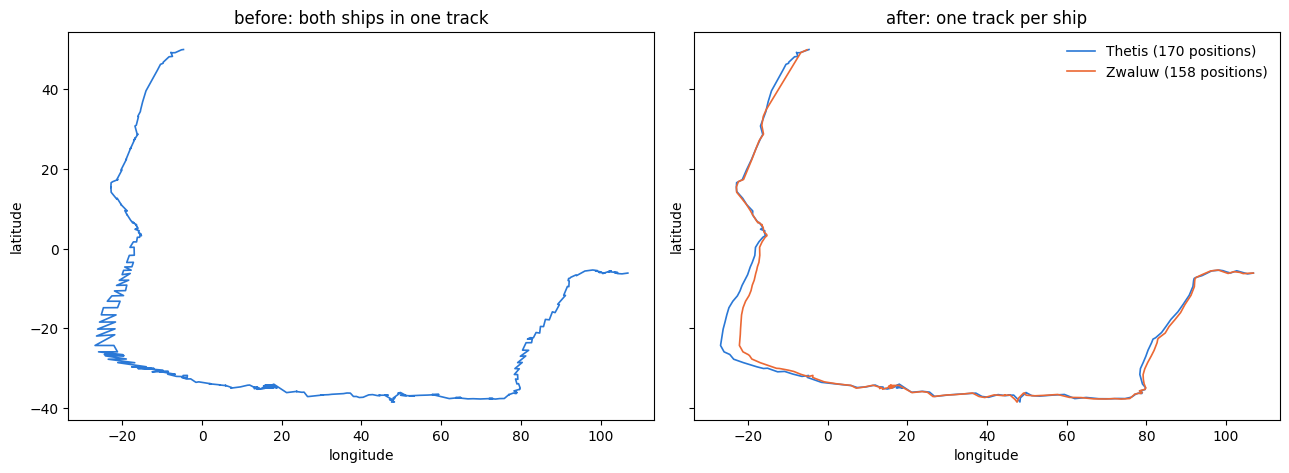

In [33]:
# Check: the example before and after
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

t = before[before["voyage_id"] == EXAMPLE].sort_values("date").dropna(subset=["latitude"])
axes[0].plot(t["longitude"], t["latitude"], color="#2a78d6", linewidth=1.2)
axes[0].set(title="before: both ships in one track")

for ship, color in [("THETIS", "#2a78d6"), ("ZWALUW", "#eb6834")]:
    t = days[days["voyage_id"] == f"{EXAMPLE} | {ship}"].dropna(subset=["latitude"])
    axes[1].plot(t["longitude"], t["latitude"], color=color, linewidth=1.2, label=f"{ship.title()} ({len(t)} positions)")
axes[1].set(title="after: one track per ship")
axes[1].legend(frameon=False)

for ax in axes:
    ax.set(xlabel="longitude", ylabel="latitude", aspect="equal")
plt.tight_layout()
plt.show()

## 2. Day-to-day steps: distance, speed, course and wind

One row per **step** = from noon of day *t−1* to noon of day *t* of the same voyage. Only consecutive days (gap of exactly 1 day) with a position on both days. Suffix `0` = previous noon (start of the step), `1` = this noon (end of the step).

| Column | Unit | Meaning |
|---|---|---|
| `distance_nm` | nautical miles (1 nm = 1,852 m = 1 minute of latitude) | haversine (great-circle) distance between the two noon positions. The shortest line between them, so the distance actually sailed (tacking, zig-zags) was longer. |
| `course` | degrees 0–360, clockwise from **true** north (0 = N, 90 = E, 180 = S, 270 = W) | direction the ship moved **to**: initial bearing from the start to the end position. This is the *course made good*: the net result of steering, tacking, leeway and currents, not the heading. Empty if the ship moved < 1 nm. |
| `hours` | hours | time between the two local noons. Not exactly 24 h: sailing east, local noon comes 4 minutes earlier per degree of longitude. |
| `speed_kn` | knots = nautical miles per hour (1 kn = 1.852 km/h ≈ 0.51 m/s) | average speed over ground for the step = `distance_nm / hours`. Includes the effect of currents. |
| `wind_dir0`, `wind_dir1` | degrees 1–360, clockwise from **true** north | direction the wind blows **from** (90 = easterly wind, 360 = northerly). CLIWOC already corrected the compass reading for magnetic declination (column `Decl`), so it uses the same north as `course`. Empty for calm or variable wind (see `calm0/1`, `variable0/1`). |
| `wind_ms0`, `wind_ms1` | m/s | wind speed converted from the logged words (Beaufort equivalents, so only a few discrete values) |
| `bft0`, `bft1` | Beaufort force 0–12 | the same as a Beaufort class |

In [34]:
# Previous record of the same voyage, next to the current one
prev_cols = ["date", "latitude", "longitude", "D", "wind_dir", "wind_ms", "beaufort", "Anchored"]
prev = days.groupby("voyage_id")[prev_cols].shift()

steps = pd.DataFrame({
    "voyage_id": days["voyage_id"],
    "ship": days["ShipName"],
    "ship_type": days["ShipType"],
    "nat": days["nat"],
    "year": days["Year"],
    "month": days["Month"],
    "date": days["date"],                                  # day the step ends
    "gap_days": (days["date"] - prev["date"]).dt.days,
    "lat0": prev["latitude"], "lon0": prev["longitude"],   # position at the previous noon
    "lat1": days["latitude"], "lon1": days["longitude"],   # position at this noon
    "anchored0": prev["Anchored"].eq("1"), "anchored1": days["Anchored"].eq("1"),
    # wind at the start (previous noon) and at the end (this noon) of the step
    "wind_dir0": prev["wind_dir"], "wind_dir1": days["wind_dir"],
    "wind_ms0": prev["wind_ms"], "wind_ms1": days["wind_ms"],
    "bft0": prev["beaufort"], "bft1": days["beaufort"],
    "calm0": prev["D"].eq(361), "calm1": days["D"].eq(361),
    "variable0": prev["D"].eq(362), "variable1": days["D"].eq(362),
})

is_first = steps["gap_days"].isna()
one_day = steps["gap_days"].eq(1)
has_pos = steps[["lat0", "lon0", "lat1", "lon1"]].notna().all(axis=1)
print(f"{len(steps):,} voyage-days")
print(f"  first day of a voyage (nothing before it): {is_first.sum():,}")
print(f"  gap longer than 1 day:                     {(steps['gap_days'] > 1).sum():,}")
print(f"  1-day gap but a position missing:          {(one_day & ~has_pos).sum():,}")

steps = steps[one_day & has_pos].copy()
print(f"-> {len(steps):,} usable steps")

280,345 voyage-days
  first day of a voyage (nothing before it): 5,461
  gap longer than 1 day:                     3,481
  1-day gap but a position missing:          21,025
-> 250,378 usable steps


In [35]:
R_NM = 3440.065   # Earth radius in nautical miles


def haversine_nm(lat0, lon0, lat1, lon1):
    """Great-circle distance in nautical miles."""
    lat0, lon0, lat1, lon1 = map(np.deg2rad, (lat0, lon0, lat1, lon1))
    a = np.sin((lat1 - lat0) / 2) ** 2 + np.cos(lat0) * np.cos(lat1) * np.sin((lon1 - lon0) / 2) ** 2
    return 2 * R_NM * np.arcsin(np.sqrt(a))


def initial_bearing(lat0, lon0, lat1, lon1):
    """Direction from point 0 to point 1 in degrees (0 = N, 90 = E)."""
    lat0, lon0, lat1, lon1 = map(np.deg2rad, (lat0, lon0, lat1, lon1))
    dlon = lon1 - lon0
    x = np.sin(dlon) * np.cos(lat1)
    y = np.cos(lat0) * np.sin(lat1) - np.sin(lat0) * np.cos(lat1) * np.cos(dlon)
    return np.rad2deg(np.arctan2(x, y)) % 360


steps["distance_nm"] = haversine_nm(steps["lat0"], steps["lon0"], steps["lat1"], steps["lon1"])
steps["course"] = initial_bearing(steps["lat0"], steps["lon0"], steps["lat1"], steps["lon1"])
steps.loc[steps["distance_nm"] < 1, "course"] = np.nan   # didn't move -> no course

# Noon-to-noon is not exactly 24 h: local noon comes 4 min earlier per degree sailed east
dlon = (steps["lon1"] - steps["lon0"] + 180) % 360 - 180
steps["hours"] = 24 - dlon / 15
steps["speed_kn"] = steps["distance_nm"] / steps["hours"]

steps[["distance_nm", "course", "hours", "speed_kn"]].describe().round(2)

,distance_nm,course,hours,speed_kn
count,250378.00,248185.00,250378.00,250378.00
mean,99.55,178.58,24.00,4.15
std,73.10,101.70,0.13,3.20
min,0.00,0.00,16.04,0.00
25%,55.39,86.24,23.93,2.31
50%,95.00,190.26,24.01,3.96
75%,137.36,258.98,24.08,5.72
max,6877.76,359.91,32.02,428.66


In [36]:
# Check on the example ship
cols = ["date", "lat0", "lon0", "lat1", "lon1", "distance_nm", "course", "hours", "speed_kn",
        "wind_dir0", "wind_dir1", "bft0", "bft1"]
steps.loc[steps["voyage_id"] == f"{EXAMPLE} | THETIS", cols].head(8).round(2)

,date,lat0,lon0,lat1,lon1,distance_nm,course,hours,speed_kn,wind_dir0,wind_dir1,bft0,bft1
253956,1789-04-15,50.00,-4.66,49.20,-6.92,100.20,242.22,24.15,4.15,55.0,190.0,3.0,3.0
253957,1789-04-16,49.20,-6.92,49.18,-7.72,31.41,268.11,24.05,1.31,190.0,133.0,3.0,5.0
253958,1789-04-17,49.18,-7.72,49.30,-7.80,7.86,336.51,24.01,0.33,133.0,211.0,5.0,4.0
253959,1789-04-18,49.30,-7.80,48.27,-7.42,63.64,166.19,23.97,2.65,211.0,224.0,4.0,5.0
253960,1789-04-19,48.27,-7.42,48.18,-8.28,34.82,261.39,24.06,1.45,224.0,358.0,5.0,3.0
253961,1789-04-20,48.18,-8.28,46.80,-9.75,102.08,216.29,24.10,4.24,358.0,225.0,3.0,0.0
253962,1789-04-21,46.80,-9.75,46.55,-9.77,15.03,183.15,24.00,0.63,225.0,168.0,0.0,3.0
253963,1789-04-22,46.55,-9.77,46.28,-10.43,31.77,239.56,24.04,1.32,168.0,22.0,3.0,2.0


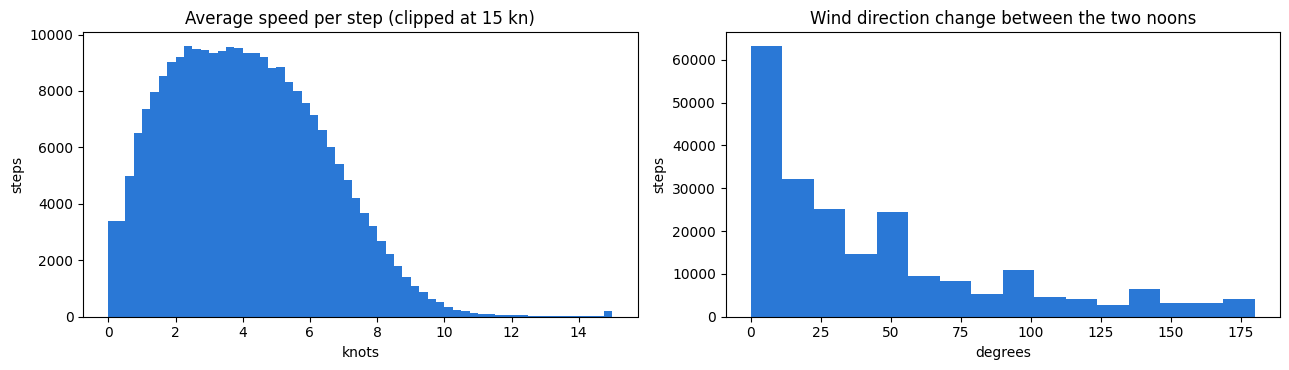

faster than 12 kn (> ~290 nm/day, suspicious): 0.21%
at anchor on either day: 1.4%
wind within 22.5° at both noons: 43%, changed by more than 90°: 15%


In [37]:
# Checks: speed distribution, and how much the wind changes between the two noons
both = steps[["wind_dir0", "wind_dir1"]].dropna()
wind_change = ((both["wind_dir1"] - both["wind_dir0"] + 180) % 360 - 180).abs()   # smallest angle, 0-180°

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(steps["speed_kn"].clip(upper=15), bins=60, color="#2a78d6")
axes[0].set(title="Average speed per step (clipped at 15 kn)", xlabel="knots", ylabel="steps")
axes[1].hist(wind_change, bins=np.arange(0, 181, 11.25), color="#2a78d6")
axes[1].set(title="Wind direction change between the two noons", xlabel="degrees", ylabel="steps")
plt.tight_layout()
plt.show()

print(f"faster than 12 kn (> ~290 nm/day, suspicious): {(steps['speed_kn'] > 12).mean():.2%}")
print(f"at anchor on either day: {(steps['anchored0'] | steps['anchored1']).mean():.1%}")
print(f"wind within 22.5° at both noons: {(wind_change <= 22.5).mean():.0%}, "
      f"changed by more than 90°: {(wind_change > 90).mean():.0%}")

## 3. Angle between course and wind vs speed

**Mean wind direction** of a step: the average of `wind_dir0` and `wind_dir1`, taken as unit vectors (so the mean of 350° and 10° is 0°, not 180°). If the wind turned more than 90° between the two noons, the mean is meaningless and the step is left out.

**Wind angle** (`wind_angle`, degrees 0–180) = smallest angle between where the wind comes **from** and where the ship goes **to**:
- 0° = wind straight from ahead (head wind),
- 90° = wind from the side (beam),
- 180° = wind straight from behind (following wind).

Wind from the left or right side is treated the same.

Expectation: square-riggers could not sail closer than about 60–70° to the wind. To get further upwind they had to tack (zig-zag), so the net speed along the course should drop at small angles.

Also left out: steps at anchor, steps where the ship didn't move (no course) and steps faster than 12 kn (position errors).

In [38]:
def angle_diff(a, b):
    """Signed smallest difference a - b in degrees, between -180 and 180."""
    return (a - b + 180) % 360 - 180


def mean_direction(a, b):
    """Mean of two directions in degrees, averaged as unit vectors."""
    a, b = np.deg2rad(a), np.deg2rad(b)
    return np.rad2deg(np.arctan2(np.sin(a) + np.sin(b), np.cos(a) + np.cos(b))) % 360


steps["wind_change"] = angle_diff(steps["wind_dir1"], steps["wind_dir0"]).abs()
steps["wind_dir_mean"] = mean_direction(steps["wind_dir0"], steps["wind_dir1"])
steps.loc[steps["wind_change"] > 90, "wind_dir_mean"] = np.nan   # wind turned too much, the mean means nothing

# Wind comes FROM wind_dir_mean, the ship goes TO course -> equal directions = head wind (0°)
steps["wind_angle"] = angle_diff(steps["wind_dir_mean"], steps["course"]).abs()

no_wind = steps["wind_dir_mean"].isna()
no_course = steps["course"].isna()
anchored = steps["anchored0"] | steps["anchored1"]
too_fast = steps["speed_kn"] > 12
print(f"{len(steps):,} steps, left out (reasons can overlap):")
print(f"  no usable mean wind (missing, calm, variable or turned > 90°): {no_wind.sum():,}")
print(f"  didn't move (no course):                                     {no_course.sum():,}")
print(f"  at anchor on either day:                                     {anchored.sum():,}")
print(f"  faster than 12 kn:                                           {too_fast.sum():,}")

sail = steps[~(no_wind | no_course | anchored | too_fast)]
print(f"-> {len(sail):,} steps")

250,378 steps, left out (reasons can overlap):
  no usable mean wind (missing, calm, variable or turned > 90°): 60,516
  didn't move (no course):                                     2,193
  at anchor on either day:                                     3,412
  faster than 12 kn:                                           521
-> 187,208 steps


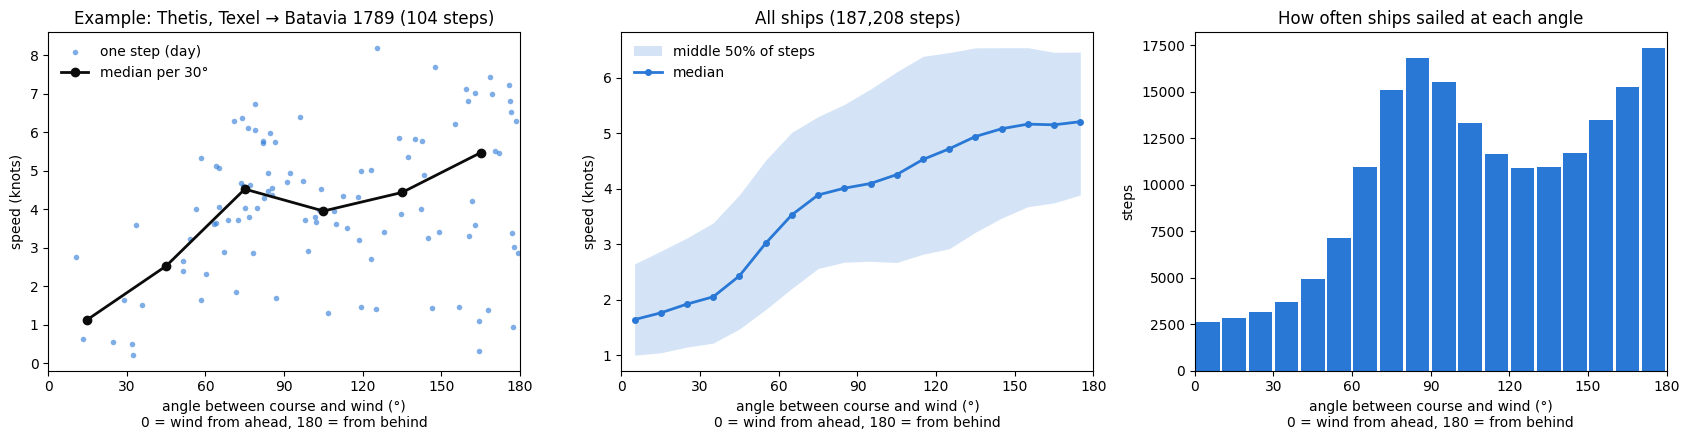

,angle,median,q25,q75,n
0,5.0,1.64,1.00,2.65,2618
1,15.0,1.76,1.05,2.88,2806
2,25.0,1.92,1.15,3.11,3155
3,35.0,2.05,1.22,3.39,3704
4,45.0,2.43,1.47,3.89,4936
5,55.0,3.02,1.82,4.51,7132
6,65.0,3.53,2.20,5.02,10938
7,75.0,3.89,2.56,5.30,15078
8,85.0,4.01,2.68,5.52,16833
9,95.0,4.09,2.69,5.79,15525


In [39]:
def speed_by_angle(data, width=10):
    """Median and quartiles of speed per wind-angle bin."""
    bins = np.arange(0, 180 + width, width)
    g = data.groupby(pd.cut(data["wind_angle"], bins, include_lowest=True), observed=False)["speed_kn"]
    return pd.DataFrame({
        "angle": bins[:-1] + width / 2,
        "median": g.median().to_numpy(),
        "q25": g.quantile(0.25).to_numpy(),
        "q75": g.quantile(0.75).to_numpy(),
        "n": g.size().to_numpy(),
    })


ex = sail[sail["voyage_id"] == f"{EXAMPLE} | THETIS"]
ex_bins = speed_by_angle(ex, width=30)
all_bins = speed_by_angle(sail)
XLABEL = "angle between course and wind (°)\n0 = wind from ahead, 180 = from behind"

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

ax = axes[0]
ax.scatter(ex["wind_angle"], ex["speed_kn"], s=16, color="#2a78d6", alpha=0.6, linewidths=0, label="one step (day)")
ax.plot(ex_bins["angle"], ex_bins["median"], color="#0b0b0b", linewidth=2, marker="o", label="median per 30°")
ax.set(title=f"Example: Thetis, Texel → Batavia 1789 ({len(ex)} steps)", ylabel="speed (knots)")
ax.legend(frameon=False)

ax = axes[1]
ax.fill_between(all_bins["angle"], all_bins["q25"], all_bins["q75"], color="#2a78d6", alpha=0.2,
                linewidth=0, label="middle 50% of steps")
ax.plot(all_bins["angle"], all_bins["median"], color="#2a78d6", linewidth=2, marker="o", markersize=4, label="median")
ax.set(title=f"All ships ({len(sail):,} steps)", ylabel="speed (knots)")
ax.legend(frameon=False)

ax = axes[2]
ax.bar(all_bins["angle"], all_bins["n"], width=9, color="#2a78d6")
ax.set(title="How often ships sailed at each angle", ylabel="steps")

for ax in axes:
    ax.set(xlabel=XLABEL, xlim=(0, 180), xticks=range(0, 181, 30))
plt.tight_layout()
plt.show()

all_bins.round(2)

### Which wind reading describes the step best?

The same steps with the wind angle computed from the start reading, the end reading and their mean. A reading that matches the step better should give a clearer pattern (slow upwind, fast downwind) and fewer steps that seem to go closer to the wind than a square-rigger can sail.

start (previous noon)  steps closer than 45° to the wind: 9.7%
end (this noon)        steps closer than 45° to the wind: 8.1%
mean of both           steps closer than 45° to the wind: 7.8%


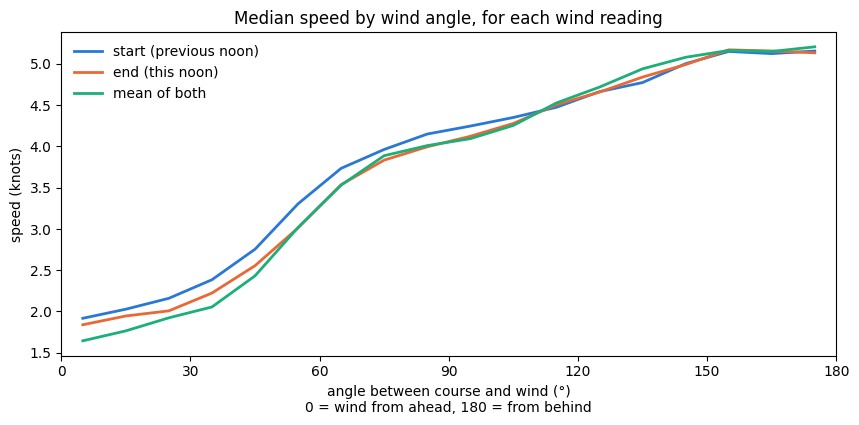

In [40]:
readings = {
    "start (previous noon)": angle_diff(sail["wind_dir0"], sail["course"]).abs(),
    "end (this noon)": angle_diff(sail["wind_dir1"], sail["course"]).abs(),
    "mean of both": sail["wind_angle"],
}

fig, ax = plt.subplots(figsize=(10, 4.2))
for (label, angle), color in zip(readings.items(), ["#2a78d6", "#eb6834", "#1baf7a"]):
    b = speed_by_angle(sail.assign(wind_angle=angle))
    ax.plot(b["angle"], b["median"], color=color, linewidth=2, label=label)
    print(f"{label:22s} steps closer than 45° to the wind: {(angle < 45).mean():.1%}")
ax.set(title="Median speed by wind angle, for each wind reading", xlabel=XLABEL, ylabel="speed (knots)",
       xlim=(0, 180), xticks=range(0, 181, 30))
ax.legend(frameon=False)
plt.show()

## 4. Position quality

How each latitude and longitude was obtained (`LatInd` / `LonInd`, see the [CLIWOC docs](https://stvno.github.io/page/cliwoc/)):

| Code | Meaning |
|---|---|
| 1 | **dead reckoning**: calculated from the logged course, speed and time since the last known position |
| 2 | **observed** ("true navigation"): from the sun or stars, or a bearing to land |
| 3, 4 | **interpolated** (by hand / automatically) |
| 5 | **inserted** known position (port, island) |
| 6 | missing |

Why it matters for speed:
- **interpolated** positions are spread evenly between two known points, so they give fake, constant speeds;
- **dead reckoning** ignores currents, so the speed is roughly the speed *through the water*;
- **observed** positions give the real speed *over ground* (currents included). But when a fix corrects several days of dead-reckoning error, the whole correction lands in one step.

Each position gets the weaker of its latitude and longitude source ("partly observed" = one observed, the other dead reckoning). Each step gets the weaker of its two positions.

In [41]:
POS_SRC = {1: "dead reckoning", 2: "observed", 3: "interpolated", 4: "interpolated", 5: "inserted", 6: "missing"}

codes = (pd.read_csv(ROOT / "data" / "CLIWOC21.tsv", sep="\t", usecols=["LatInd", "LonInd"], dtype=str)
           .apply(pd.to_numeric, errors="coerce"))   # LonInd is stored as text, with a few junk values
days["lat_src"] = codes["LatInd"]
days["lon_src"] = codes["LonInd"]

with_pos = days[days["latitude"].notna()]
pd.crosstab(with_pos["lat_src"].map(POS_SRC), with_pos["lon_src"].map(POS_SRC), margins=True,
            rownames=["latitude from"], colnames=["longitude from"])

longitude from,dead reckoning,inserted,interpolated,observed,All
latitude from,,,,,
dead reckoning,71023,89,11041,19915,102068
inserted,4,3382,0,2,3388
interpolated,646,6,3087,764,4503
observed,41547,65,14518,93267,149397
All,113220,3542,28646,113948,259356


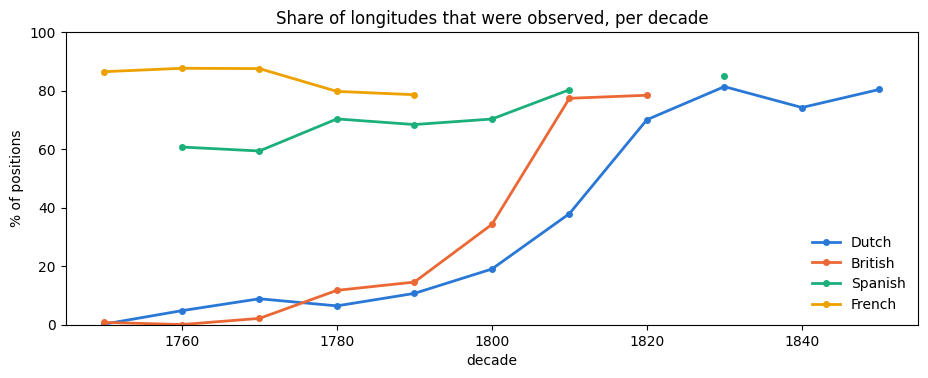

In [42]:
# Longitude at sea needed a marine chronometer or lunar-distance tables, which spread from roughly the 1770s
dec = with_pos.assign(decade=with_pos["Year"] // 10 * 10, lon_observed=with_pos["lon_src"].eq(2))
share = dec.groupby(["decade", "nat"])["lon_observed"].agg(["mean", "size"])
share = share.loc[share["size"] >= 200, "mean"].unstack() * 100   # only decades with enough positions

fig, ax = plt.subplots(figsize=(11, 3.8))
for nat, color in [("DUTCH", "#2a78d6"), ("BRITISH", "#eb6834"), ("SPANISH", "#1baf7a"), ("FRENCH", "#eda100")]:
    if nat in share:
        ax.plot(share.index, share[nat], color=color, linewidth=2, marker="o", markersize=4, label=nat.title())
ax.set(title="Share of longitudes that were observed, per decade", xlabel="decade", ylabel="% of positions",
       ylim=(0, 100))
ax.legend(frameon=False)
plt.show()

In [43]:
QUALITY = ["observed", "partly observed", "dead reckoning", "interpolated / inserted"]   # best -> worst
# One fixed colour per category, used in every chart (gray = not a real measurement)
QUALITY_COLORS = {"observed": "#2a78d6", "partly observed": "#1baf7a", "dead reckoning": "#eb6834",
                  "interpolated / inserted": "#9a9893"}


def position_quality(lat_src, lon_src):
    """Rank 0-3 (index in QUALITY) of one position: the weaker of its latitude and longitude source."""
    rank = pd.Series(2, index=lat_src.index)                        # dead reckoning
    rank[(lat_src == 2) | (lon_src == 2)] = 1                       # one of the two observed
    rank[(lat_src == 2) & (lon_src == 2)] = 0                       # both observed
    rank[lat_src.isin([3, 4, 5]) | lon_src.isin([3, 4, 5])] = 3     # interpolated or inserted
    return rank


rank_end = position_quality(days["lat_src"], days["lon_src"])
rank_start = rank_end.groupby(days["voyage_id"]).shift()

# A step is only as good as its weaker position
step_rank = np.maximum(rank_start.reindex(steps.index), rank_end.reindex(steps.index)).astype(int)
steps["pos_quality"] = pd.Categorical.from_codes(step_rank, categories=QUALITY, ordered=True)

counts = steps["pos_quality"].value_counts(sort=False)
pd.DataFrame({"steps": counts, "share_%": (counts / counts.sum() * 100).round(1)})

,steps,share_%
pos_quality,,
observed,81030,32.4
partly observed,58227,23.3
dead reckoning,74528,29.8
interpolated / inserted,36593,14.6


In [44]:
# Day-to-day change in speed: interpolated positions should give suspiciously constant speeds
g = steps.groupby("voyage_id")
next_day = g["date"].diff().dt.days.eq(1)
steps["speed_change"] = g["speed_kn"].diff().abs().where(next_day)

sail = steps.loc[sail.index]   # refresh the analysis subset so it has the new columns

sail.groupby("pos_quality", observed=False).agg(
    steps=("speed_kn", "size"),
    median_speed=("speed_kn", "median"),
    q25=("speed_kn", lambda s: s.quantile(0.25)),
    q75=("speed_kn", lambda s: s.quantile(0.75)),
    pct_same_speed_as_day_before=("speed_change", lambda s: (s.dropna() < 0.1).mean() * 100),
).round(2)

,steps,median_speed,q25,q75,pct_same_speed_as_day_before
pos_quality,,,,,
observed,63038,5.02,3.18,6.62,5.66
partly observed,45406,3.96,2.51,5.46,6.20
dead reckoning,53799,4.00,2.42,5.69,5.91
interpolated / inserted,24965,3.79,2.28,5.36,10.00


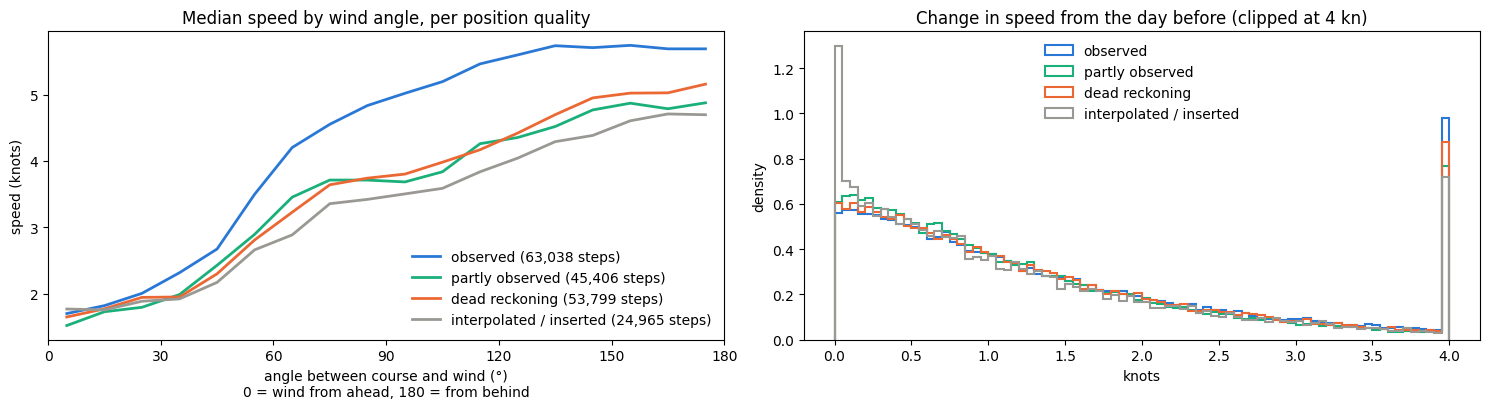

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))

for q in QUALITY:
    part = sail[sail["pos_quality"] == q]
    b = speed_by_angle(part)
    axes[0].plot(b["angle"], b["median"], color=QUALITY_COLORS[q], linewidth=2, label=f"{q} ({len(part):,} steps)")
    axes[1].hist(part["speed_change"].dropna().clip(upper=4), bins=80, density=True, histtype="step",
                 color=QUALITY_COLORS[q], linewidth=1.5, label=q)

axes[0].set(title="Median speed by wind angle, per position quality", xlabel=XLABEL, ylabel="speed (knots)",
            xlim=(0, 180), xticks=range(0, 181, 30))
axes[1].set(title="Change in speed from the day before (clipped at 4 kn)", xlabel="knots", ylabel="density")
for ax in axes:
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [46]:
# Decision (check the results above first): interpolated / inserted positions don't measure the ship's speed,
# so leave them out. pos_quality stays as a column: a currents analysis would use only "observed" steps.
sail = sail[sail["pos_quality"] != "interpolated / inserted"]
print(f"-> {len(sail):,} steps left")

-> 162,243 steps left


### Whole voyages: speed vs wind, coloured by how the positions were measured

Voyages we can follow almost day by day:
- at least 60 days long,
- a step on at least 90% of the days (few gaps),
- at least 60 steps with usable wind,
- known port of departure and destination.

From those, the voyage with the most wind steps per nationality and period (before / after 1800). Each row:
- **left**: the track, each noon position coloured by how it was obtained;
- **right**: speed against wind angle, each step coloured by its weaker position, black line = median per 30°.

Interpolated steps are shown here on purpose (gray), even though they were removed from `sail`.

In [47]:
# Steps usable for speed vs wind, *including* interpolated ones (so we can see them in the plots)
usable = (steps["wind_angle"].notna() & steps["course"].notna()
          & ~(steps["anchored0"] | steps["anchored1"]) & steps["speed_kn"].le(12))
plot_steps = steps[usable]

# One row per voyage: how long it is and how complete (share of days that have a step)
voy = days.groupby("voyage_id").agg(
    ship=("ShipName", "first"), nat=("nat", "first"), origin=("VoyageFrom", "first"),
    dest=("VoyageTo", "first"), start=("date", "min"), end=("date", "max"),
)
voy["days"] = (voy["end"] - voy["start"]).dt.days
voy["steps"] = steps.groupby("voyage_id").size()
voy["wind_steps"] = plot_steps.groupby("voyage_id").size()
voy["complete"] = (voy["steps"] / voy["days"]).round(2)   # 1 = a step on every day

# % of each voyage's wind steps per position quality
quality_share = pd.crosstab(plot_steps["voyage_id"], plot_steps["pos_quality"], normalize="index") * 100
quality_share.columns = quality_share.columns.astype(str)
voy = voy.join(quality_share.reindex(columns=QUALITY, fill_value=0).round(0))

candidates = voy[(voy["days"] >= 60) & (voy["complete"] >= 0.9) & (voy["wind_steps"] >= 60)
                 & voy["origin"].notna() & voy["dest"].notna() & (voy["nat"] != "OTHER")].copy()
candidates["period"] = np.where(candidates["start"].dt.year < 1800, "before 1800", "1800 and later")
print(f"{len(candidates)} voyages are ≥ 60 days long, have a step on ≥ 90% of the days and ≥ 60 steps with wind")

# For each nationality and period: the voyage with the most wind steps
picked = (candidates.sort_values("wind_steps", ascending=False)
          .groupby(["nat", "period"]).head(1)
          .sort_values(["nat", "start"]))
picked[["ship", "nat", "period", "origin", "dest", "start", "days", "wind_steps", "complete", *QUALITY]]

824 voyages are ≥ 60 days long, have a step on ≥ 90% of the days and ≥ 60 steps with wind


,ship,nat,period,origin,dest,start,days,wind_steps,complete,observed,partly observed,dead reckoning,interpolated / inserted
voyage_id,,,,,,,,,,,,,
BL L/MAR/B/551C | 17660402 | TILBURY,TILBURY,BRITISH,before 1800,JAVA HEAD,FALMOUTH,1766-04-02,187,146.0,0.90,0.0,71.0,9.0,21.0
BL L/MAR/B/255D | 18040614 | PERSEVERENCE,PERSEVERENCE,BRITISH,1800 and later,PORTSMOUTH,WHAMPOE,1804-06-14,196,130.0,0.91,71.0,11.0,14.0,5.0
VOC_152_11419 | 17650201 | VLIETLUST,VLIETLUST,DUTCH,before 1800,RAMMEKENS,CEYLON,1765-02-03,151,110.0,0.91,0.0,38.0,15.0,47.0
"EXTRACT B, REIS 6 | 18480530 | EOLUS",EOLUS,DUTCH,1800 and later,AKIJAB,NIEUWEDIEP,1848-05-30,193,137.0,0.96,85.0,7.0,3.0,6.0
NIWI-F-1573 | 17871001 | LA BOUSSOLE,LA BOUSSOLE,FRENCH,before 1800,AVATSCHA,NOUVELLE HOLLANDE,1787-10-01,115,91.0,1.00,0.0,59.0,0.0,41.0
"CORREOS, 193B R1 | 17680615 | SAN FERNANDO",SAN FERNANDO,SPANISH,before 1800,LA CORUÑA,MONTEVIDEO,1768-06-15,157,134.0,1.00,0.0,99.0,0.0,1.0
MS. 168 (2) | 18190131 | SAN JULIAN,SAN JULIAN,SPANISH,1800 and later,CALCUTA,CÁDIZ,1819-01-31,146,128.0,0.95,93.0,0.0,7.0,0.0


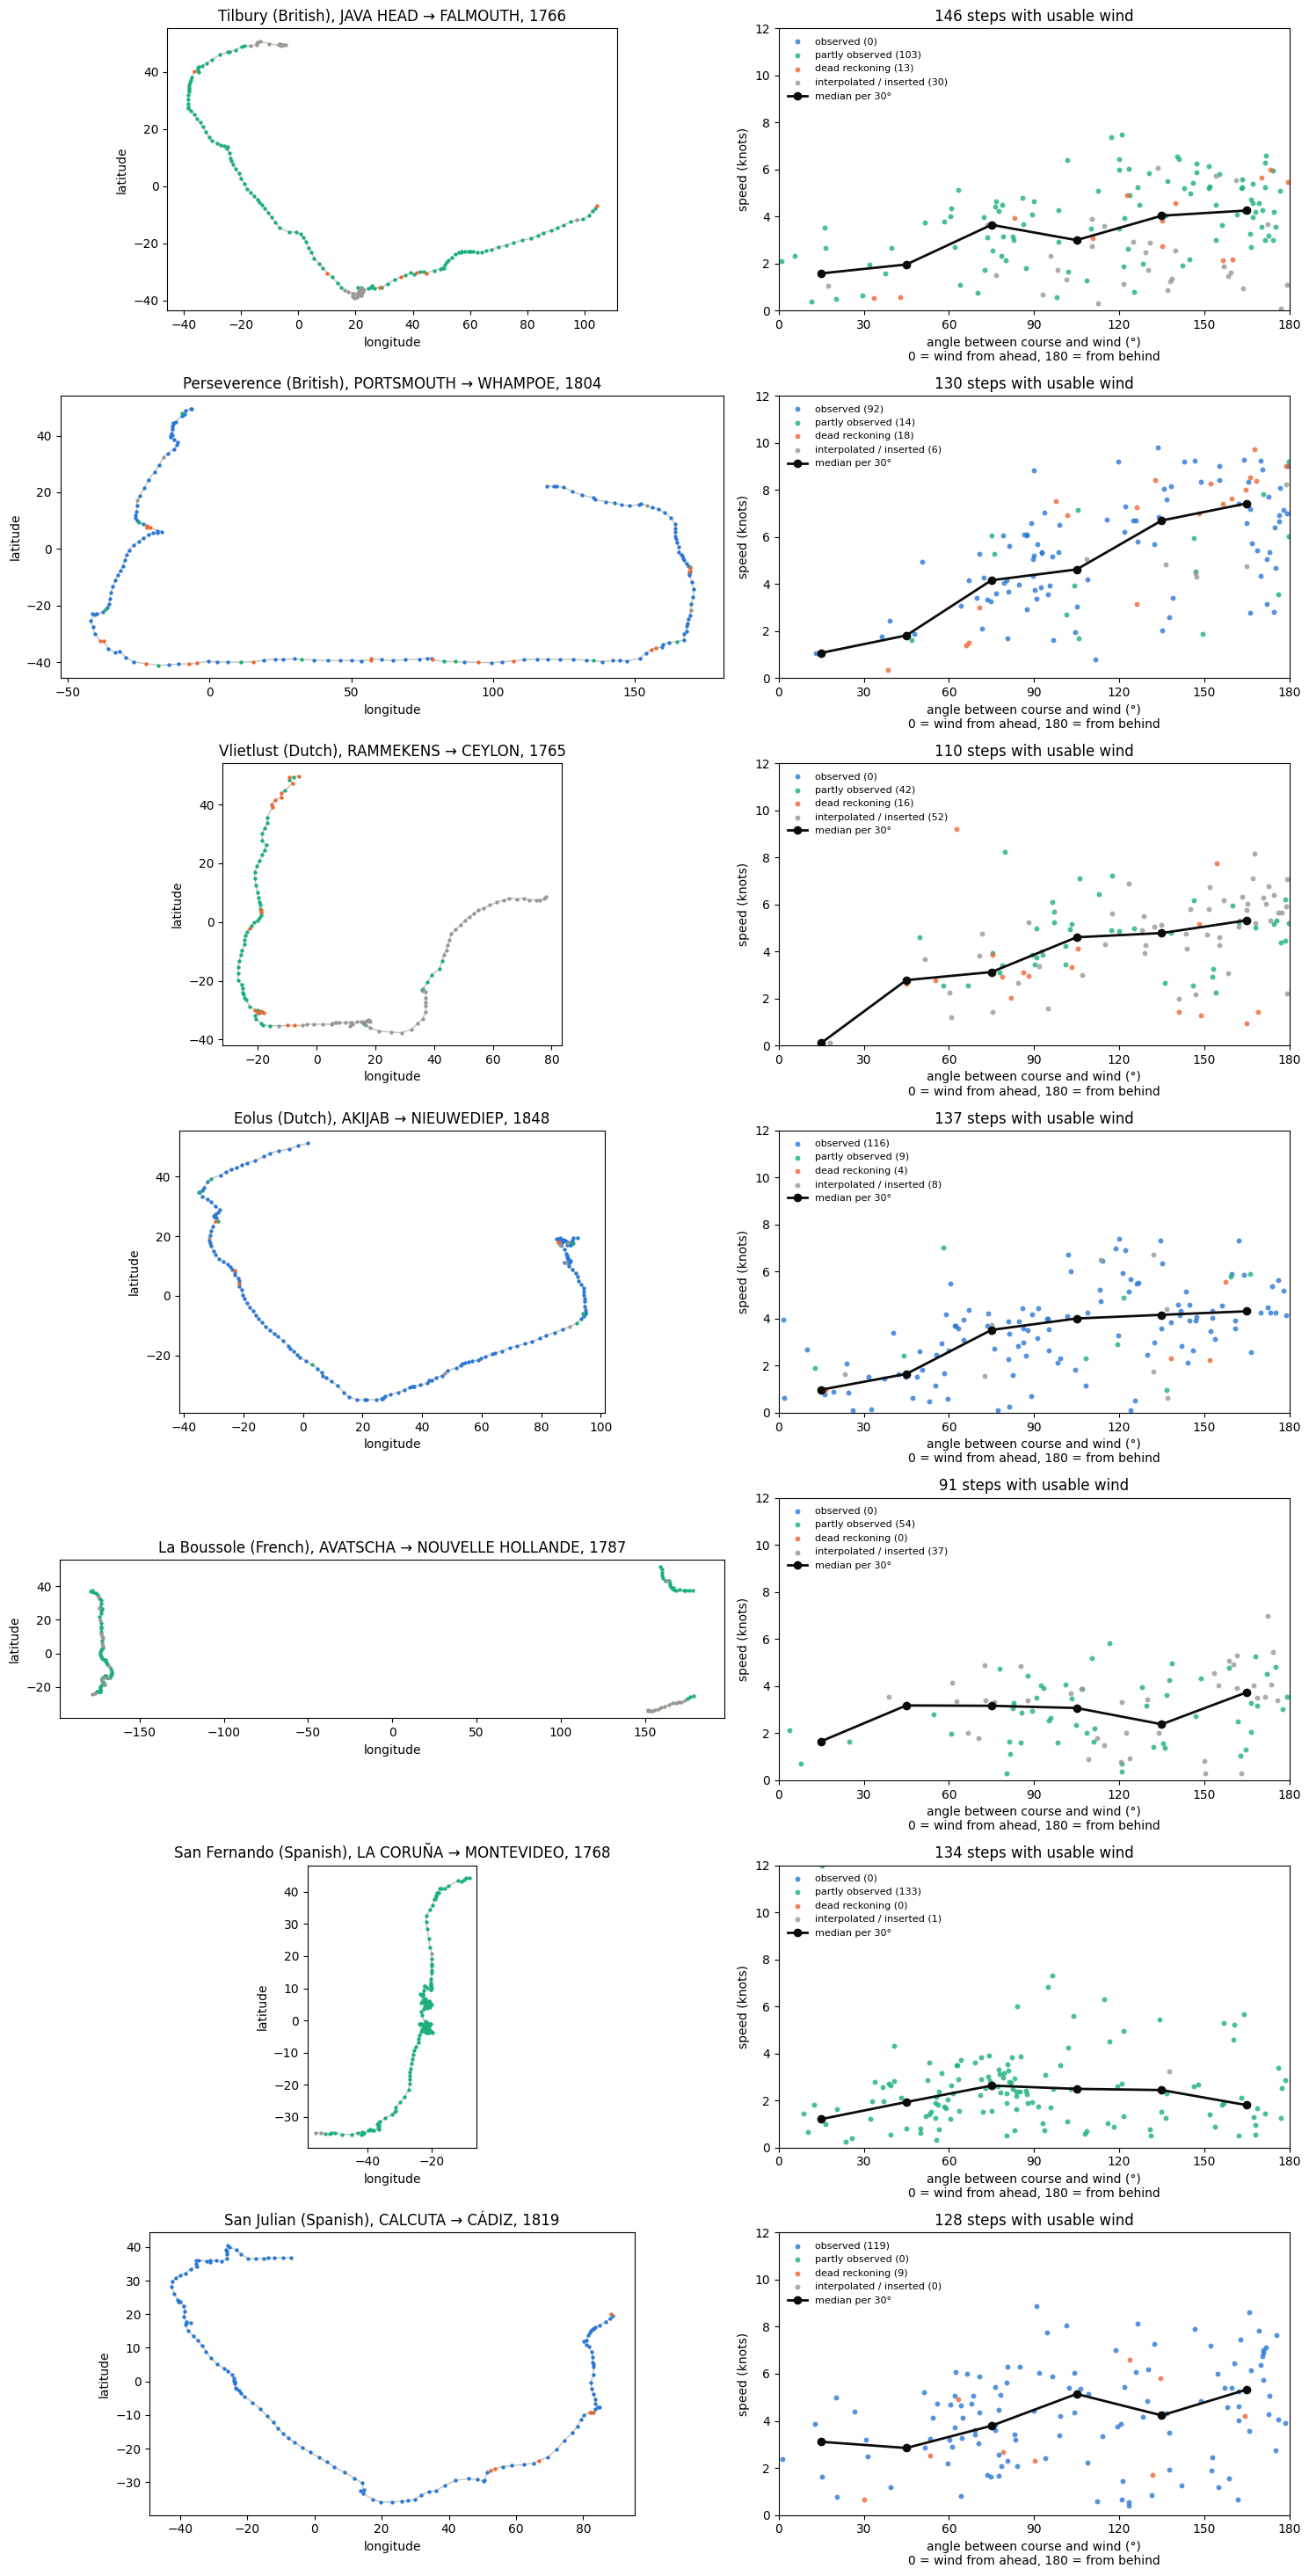

In [48]:
def track_lines(lon, lat):
    """Break the line where the track crosses the 180° meridian."""
    lon, lat = np.asarray(lon, float), np.asarray(lat, float)
    jump = np.where(np.abs(np.diff(lon)) > 180)[0] + 1
    return np.insert(lon, jump, np.nan), np.insert(lat, jump, np.nan)


CHOSEN = list(picked.index)   # or put any voyage_id from `candidates` here

fig, axes = plt.subplots(len(CHOSEN), 2, figsize=(15, 4.2 * len(CHOSEN)),
                         gridspec_kw={"width_ratios": [1.3, 1]}, squeeze=False)

for (ax_map, ax_speed), vid in zip(axes, CHOSEN):
    v = voy.loc[vid]

    # Left: the track, each noon position coloured by how it was obtained
    track = days[(days["voyage_id"] == vid) & days["latitude"].notna()]
    track_quality = rank_end.loc[track.index].map(dict(enumerate(QUALITY)))
    ax_map.plot(*track_lines(track["longitude"], track["latitude"]), color="#c3c2b7", linewidth=1, zorder=1)
    for q in QUALITY:
        p = track[track_quality == q]
        ax_map.scatter(p["longitude"], p["latitude"], s=10, color=QUALITY_COLORS[q], linewidths=0, zorder=2)
    ax_map.set(title=f"{v['ship'].title()} ({v['nat'].title()}), {v['origin']} → {v['dest']}, {v['start']:%Y}",
               xlabel="longitude", ylabel="latitude", aspect="equal")

    # Right: speed vs wind angle, each step coloured by its weaker position
    s = plot_steps[plot_steps["voyage_id"] == vid]
    for q in QUALITY:
        p = s[s["pos_quality"] == q]
        ax_speed.scatter(p["wind_angle"], p["speed_kn"], s=18, color=QUALITY_COLORS[q], alpha=0.8,
                         linewidths=0, label=f"{q} ({len(p)})")
    b = speed_by_angle(s, width=30)
    ax_speed.plot(b["angle"], b["median"], color="#0b0b0b", linewidth=2, marker="o", label="median per 30°")
    ax_speed.set(title=f"{len(s)} steps with usable wind", xlabel=XLABEL, ylabel="speed (knots)",
                 xlim=(0, 180), xticks=range(0, 181, 30), ylim=(0, 12))
    ax_speed.legend(frameon=False, fontsize=8, loc="upper left")

plt.tight_layout()
plt.show()

## Findings so far

1. **Cleaning:** 26 logbook IDs contained several ships (e.g. *Thetis* + *Zwaluw*), so the voyage key now includes the ship name. 6,393 duplicate rows removed → 280,345 voyage-days → 250,378 day-to-day steps.
2. **Wind directions use true north:** CLIWOC already corrected the compass readings for magnetic declination (checked: `D` = compass reading + `Decl`), the same reference as our computed course.
3. **The mean of the two noon readings** describes a step best: fewest steps that seem impossibly close to the wind (7.8%, vs 8.1% with the end reading and 9.7% with the start reading).
4. **Speed vs wind angle:** the median rises from ~1.6 kn with the wind from ahead to ~5.2 kn with the wind from behind. Few days closer than 45° to the wind: square-riggers couldn't sail that close and had to tack.
5. **Position quality:** 32% observed, 23% partly observed, 30% dead reckoning, 15% interpolated/inserted. Interpolated steps repeat the previous day's speed much more often (10% vs ~6%), so they are excluded. Before ~1800, British and Dutch longitudes were mostly dead reckoning. The French/Spanish "observed" labels are doubtful: those records rarely contain a separate dead-reckoning position.
6. **Does the measurement type matter?** Over all data, observed steps look faster and more tied to the wind. But *within the same voyage* (33 mixed voyages before 1800; the charts were removed to keep this notebook short) no type was consistently better: partly observed beat dead reckoning in only 42% of the voyages. So the difference is mostly *which ships and which era* have observed positions, not the measurement itself. We keep observed + partly observed + dead reckoning, with `pos_quality` as a control variable.

## Next steps

1. **Wind force:** heatmap wind angle × Beaufort → median speed, then a **polar diagram** with one line per wind band (light 1–3, moderate 4–5, fresh 6–7, gale 8+). Wind force of a step = mean of `bft0` and `bft1`.
2. **Wind-force translation check:** speed vs Beaufort per nationality (do British "force 8" days sail like Dutch "force 5–6" days?).
3. **Performance index** = speed ÷ typical speed for that wind angle and force, compared by ship type, nationality, decade and days at sea.
4. Later: a model (regression → small MLP) predicting speed from these features; optionally currents (NOAA drifter climatology, only meaningful for observed positions).